In [1]:
!pip install pytorch-tabnet -q
from google.colab import files
uploaded = files.upload()   # utils.py, dataset_base.csv, dataset_with_technicals.csv

In [2]:
!pip install pytorch-tabnet

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pytorch_tabnet.tab_model import TabNetRegressor
from sklearn.preprocessing import StandardScaler
from utils import load_split, evaluate

paths = {"base": "dataset_base.csv", "tech": "dataset_with_technicals.csv"}
print(torch.__version__)

2.11.0+cu130


In [4]:
def run_tabnet(path, seeds=range(3), n_d=8, n_a=8, n_steps=3, lambda_sparse=1e-3):
    X_tr, X_te, y_tr, y_te = load_split(path)
    n_val = int(len(X_tr) * 0.15)
    X_sub, X_val = X_tr.iloc[:-n_val], X_tr.iloc[-n_val:]
    y_sub, y_val = y_tr.iloc[:-n_val], y_tr.iloc[-n_val:]

    sc = StandardScaler().fit(X_sub)
    y_mu, y_sd = y_sub.mean(), y_sub.std()

    Xs, Xv, Xt = sc.transform(X_sub), sc.transform(X_val), sc.transform(X_te)
    ys = ((y_sub - y_mu) / y_sd).values.reshape(-1, 1)
    yv = ((y_val - y_mu) / y_sd).values.reshape(-1, 1)

    preds, masks, last_hist = [], [], None
    for s in seeds:
        torch.manual_seed(s); np.random.seed(s)
        model = TabNetRegressor(
            n_d=n_d, n_a=n_a, n_steps=n_steps, gamma=1.5,
            lambda_sparse=lambda_sparse,
            optimizer_params=dict(lr=2e-3, weight_decay=1e-3),
            seed=s, verbose=0,
        )
        model.fit(
            Xs, ys, eval_set=[(Xv, yv)], eval_metric=["rmse"],
            max_epochs=200, patience=20, batch_size=64, virtual_batch_size=32,
        )
        preds.append(model.predict(Xt).ravel() * y_sd + y_mu)
        masks.append(model.explain(Xt)[0].mean(axis=0))
        last_hist = model.history
        print(f"  seed {s}: stopped after {len(model.history['loss'])} epochs, "
              f"best val RMSE (std. units) = {model.best_cost:.3f}", flush=True)

    imp = pd.Series(np.mean(masks, axis=0), index=X_tr.columns)
    return np.mean(preds, axis=0), y_te, y_tr.mean(), imp, last_hist


results, store = [], {}
for k, p in paths.items():
    print(f"--- {k} ---", flush=True)
    pred, y_te, mu, imp, hist = run_tabnet(p)
    store[k] = dict(pred=pred, y_te=y_te, imp=imp, hist=hist)
    results.append({**evaluate(y_te, pred, mu, "TabNet"), "data": k})

res = pd.DataFrame(results).set_index(["data", "model"])
print(res.round(4))
res.to_csv("tabnet_results.csv")

--- base ---

Early stopping occurred at epoch 53 with best_epoch = 33 and best_val_0_rmse = 1.25297
  seed 0: stopped after 54 epochs, best val RMSE (std. units) = 1.253


/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 29 with best_epoch = 9 and best_val_0_rmse = 1.26248
  seed 1: stopped after 30 epochs, best val RMSE (std. units) = 1.262


/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 39 with best_epoch = 19 and best_val_0_rmse = 1.21514
  seed 2: stopped after 40 epochs, best val RMSE (std. units) = 1.215
--- tech ---


...

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 27 with best_epoch = 7 and best_val_0_rmse = 1.26551
  seed 1: stopped after 28 epochs, best val RMSE (std. units) = 1.266


/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 78 with best_epoch = 58 and best_val_0_rmse = 1.25933
  seed 2: stopped after 79 epochs, best val RMSE (std. units) = 1.259
               RMSE     MAE      R2  R2_OOS  DirAcc
data model                                         
base TabNet  0.0370  0.0260 -0.0175 -0.0163  0.5029
tech TabNet  0.0364  0.0259  0.0253  0.0263  0.5434


/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


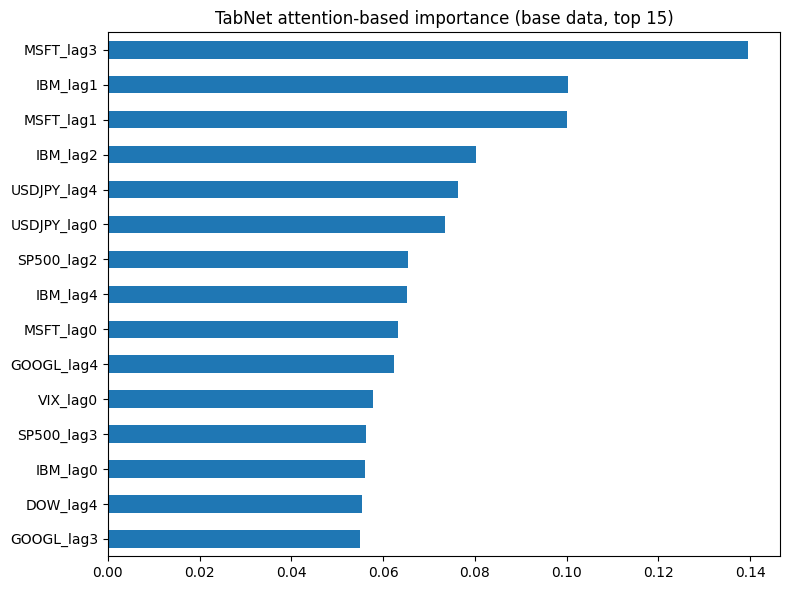

MSFT_lag3      0.1395
IBM_lag1       0.1002
MSFT_lag1      0.1001
IBM_lag2       0.0802
USDJPY_lag4    0.0763
USDJPY_lag0    0.0735
SP500_lag2     0.0654
IBM_lag4       0.0653
MSFT_lag0      0.0631
GOOGL_lag4     0.0624
dtype: float64


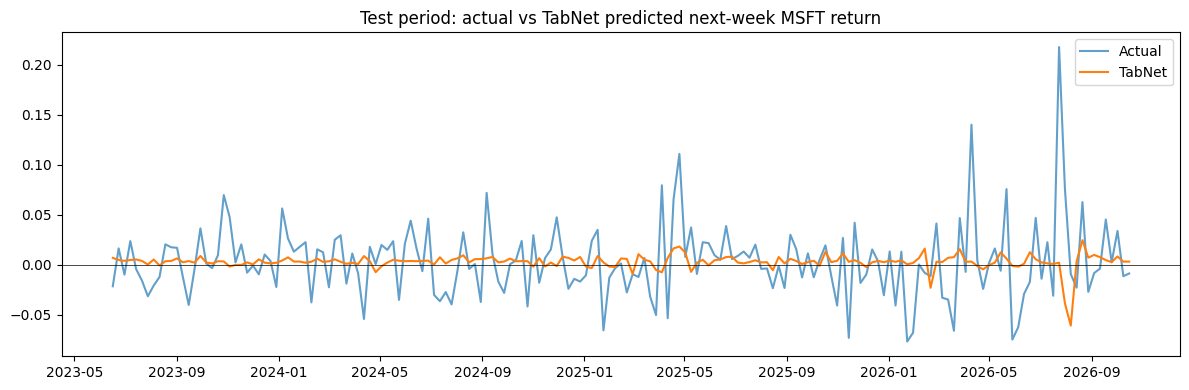

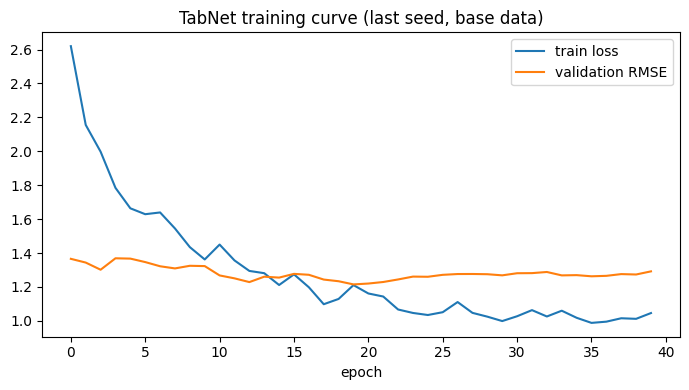

In [5]:
k = "base"

# Feature importance from attention masks
imp = store[k]["imp"].sort_values()
plt.figure(figsize=(8, 6))
imp.tail(15).plot.barh(title="TabNet attention-based importance (base data, top 15)")
plt.tight_layout()
plt.savefig("15_tabnet_importance.png", dpi=150)
plt.show()
print(store[k]["imp"].sort_values(ascending=False).head(10).round(4))

# Predicted vs actual
plt.figure(figsize=(12, 4))
plt.plot(store[k]["y_te"].index, store[k]["y_te"].values, label="Actual", alpha=0.7)
plt.plot(store[k]["y_te"].index, store[k]["pred"], label="TabNet")
plt.axhline(0, color="k", lw=0.5)
plt.title("Test period: actual vs TabNet predicted next-week MSFT return")
plt.legend(); plt.tight_layout()
plt.savefig("16_tabnet_pred_vs_actual.png", dpi=150)
plt.show()

# Loss curve (last seed)
h = store[k]["hist"]
plt.figure(figsize=(7, 4))
plt.plot(h["loss"], label="train loss")
plt.plot(h["val_0_rmse"], label="validation RMSE")
plt.title("TabNet training curve (last seed, base data)")
plt.xlabel("epoch"); plt.legend(); plt.tight_layout()
plt.savefig("17_tabnet_loss_curve.png", dpi=150)
plt.show()

In [6]:
from google.colab import files
for f in ["tabnet_results.csv", "15_tabnet_importance.png",
          "16_tabnet_pred_vs_actual.png", "17_tabnet_loss_curve.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>